# Room acoustics: three models of the same room

A 6 × 5 × 4 m room with an absorption coefficient of 0.2 on every wall, computed with three models of PyTTa and analysed with `RoomAnalysis`:

1. the image source method of Allen and Berkley (`rooms.image_source_ir`), with specular walls;
2. stochastic ray tracing (`rays.trace`), with diffuse walls;
3. the statistical model of Kuttruff (`generate.stochastic_ir`), with the reverberation time of Eyring.

Sabine and Eyring give the expected reverberation times.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pytta

fs = 48000
L = (6., 5., 4.)
alpha = 0.2
V, S = np.prod(L), 2 * (L[0] * L[1] + L[0] * L[2] + L[1] * L[2])
src, rcv = [1.5, 1.2, 1.4], [4.2, 3.1, 2.2]
sabine = 0.161 * V / (S * alpha)
eyring = 0.161 * V / (-S * np.log(1 - alpha))
print(f'Sabine {sabine:.3f} s, Eyring {eyring:.3f} s')

Sabine 0.653 s, Eyring 0.585 s


Image sources: the reflection factor of each wall is √(1 − α). With specular walls a shoebox does not have a diffuse field, and its decay is known to be slower than that of Eyring.

In [2]:
ism = pytta.rooms.image_source_ir(L, src, rcv, fs, duration=1.0, reflection=np.sqrt(1 - alpha))
ism_analysis = pytta.RoomAnalysis(ism, nthOct=1, minFreq=500, maxFreq=4000)
print('image sources, T30 [s]', np.round(ism_analysis.T30, 3))

image sources, T30 [s] [0.701 0.626 0.632 0.663]


Ray tracing with diffuse reflections gives an energy histogram; its backward integral gives the decay curve and T30 directly.

ray tracing, T30 0.611 s


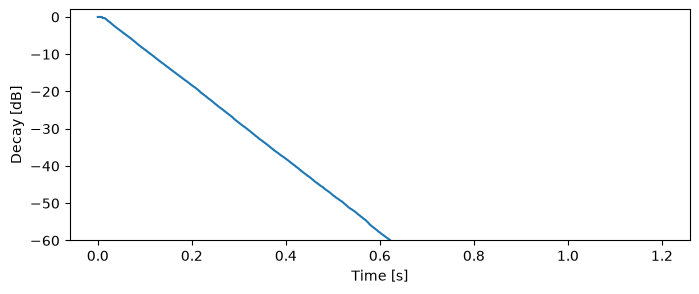

In [3]:
t, hist = pytta.rays.trace(pytta.rays.shoebox(*L, alpha, scattering=1.), src, rcv,
                          numRays=20000, duration=1.2, seed=3)
edc = np.cumsum(hist[::-1])[::-1]
level = 10 * np.log10(edc / edc[0])
i5, i35 = np.argmax(level < -5), np.argmax(level < -35)
T30 = -60 / np.polyfit(t[i5:i35], level[i5:i35], 1)[0]
print(f'ray tracing, T30 {T30:.3f} s')
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, level)
ax.set(xlabel='Time [s]', ylabel='Decay [dB]', ylim=(-60, 2))
plt.show()

The statistical model with the reverberation time of Eyring, analysed in octave bands.

In [4]:
stochastic = pytta.generate.stochastic_ir(eyring, V, distance=3., samplingRate=fs, seed=4)
st = pytta.RoomAnalysis(stochastic, nthOct=1, minFreq=125, maxFreq=4000)
print('bands  [Hz]', np.round(st.bands))
print('T30    [s] ', np.round(st.T30, 3))
print('EDT    [s] ', np.round(st.EDT, 3))
print('C80    [dB]', np.round(st.C80, 2))
print('D50    [%] ', np.round(st.D50, 1))

bands  [Hz] [ 125.  250.  500. 1000. 2000. 4000.]
T30    [s]  [0.602 0.573 0.613 0.58  0.587 0.57 ]
EDT    [s]  [0.725 0.728 0.505 0.543 0.645 0.556]
C80    [dB] [9.21 6.19 8.88 8.61 7.11 8.99]
D50    [%]  [76.7 65.4 81.9 72.3 69.  77.7]


For the decay alone, an exponential with reverberation time T, C80 = 10 lg(e^(13.82 × 0.08 / T) − 1) and D50 = 1 − e^(−13.82 × 0.05 / T). The direct sound at 3 m adds early energy, so the values of the response tend to be higher, and they vary from band to band with the random reflections of the model.

In [5]:
a = 13.8155 / eyring
print(f'expected C80 {10 * np.log10(np.exp(a * 0.08) - 1):.2f} dB, D50 {100 * (1 - np.exp(-a * 0.05)):.1f} %')

expected C80 7.49 dB, D50 69.3 %
